# ML exploration — colonias × red hidrográfica

Genera `colonias_hidrografia.csv`: una fila por colonia de la ciudad de Hermosillo con su macro-sector y los **3 segmentos de la red hidrográfica más cercanos** a su centroide, más una clasificación de cercanía en 4 niveles.

| columna | contenido |
|---|---|
| `colonia_id` | identificador DCAH de la colonia (solo `locality_code == "0001"`, la ciudad) |
| `sector` | macro-sector Norte/Centro/Sur con el procedimiento de `05-AAMM-analisis-geoespacial_subc_colonias` |
| `id_seg_1..3` | `ID` de los 3 segmentos `hl` más cercanos al centroide de la colonia |
| `dist_seg_1..3` | distancia del centroide al segmento, en metros (EPSG:6372) |
| `nivel_cercania` | Muy cercano / Cercano / Lejano / Muy lejano, por K-Means sobre las 3 distancias (método de `08-AAMM-eda-baches-hidrografia`) |

**Fuentes:** `colonias_hermosillo.gpkg` (DCAH), `subc_hermosillo.gpkg` capa `hl` (INEGI, 4 subcuencas consolidadas), `distritos_sectores_hermosillo_PDU_2025.csv` (Tabla III.1 del PDU).

**Notas de método:**
- La distancia se mide del **centroide** de la colonia al cauce — una colonia grande atravesada por un cauce puede quedar "lejana".
- Se conservan los segmentos `ENABLED = 0`: son cauces reales que el INEGI solo excluye de la red lógica por ciclos/bifurcaciones (y así lo hace la libreta 08).

In [1]:
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import box
from sklearn.cluster import KMeans

from project_name.text import normalize_name

DATA = Path("../../data")
EXPERIMENT = Path("notebook_experimentation_data")
METRICO = 6372  # ITRF2008 / México, distancias en metros

colonias = gpd.read_file(DATA / "processed/aguah/colonias_hermosillo.gpkg")
pdu = pd.read_csv(
    DATA / "external/distritos_sectores_hermosillo_PDU_2025.csv",
    encoding="utf-8-sig",
)

In [2]:
# la ciudad se aproxima disolviendo los asentamientos DCAH con
# locality_code "0001" (el codigo viaja como texto en los datos procesados)
colonias_ciudad = colonias[colonias["locality_code"] == "0001"].copy()
colonias_ciudad = colonias_ciudad.to_crs(METRICO)
ciudad_union = colonias_ciudad.union_all()

print(f"{len(colonias_ciudad)} colonias en la ciudad de Hermosillo")

762 colonias en la ciudad de Hermosillo


## Sector por colonia

Procedimiento de la libreta 05: los 9 sectores de la **Tabla III.1 del PDU de Hermosillo (generación 2025+)** se agrupan en 3 macro-sectores:

- **Norte** ← Noroeste (`NW`), Norte (`NN`), Noreste (`NE`)
- **Centro** ← Oeste (`WW`), Centro (`C`), Este (`EE`)
- **Sur** ← Suroeste (`SW`), Sur (`SS`), Sureste (`SE`)

Tres pasadas:
1. `pdu_directo` — match exacto del nombre normalizado de la colonia contra el lookup PDU (nombres listados en más de un macro-sector son ambiguos y quedan fuera).
2. `pdu_prefijo` — rescata nombres INEGI que empiezan con un nombre PDU (p. ej. "X RESIDENCIAL II" → "X RESIDENCIAL").
3. `banda_latitud` — el **sector final** lo decide la banda horizontal que cubre la mayor parte del área de la colonia (`Y_NORTE_CENTRO = 1,920,000` y `Y_CENTRO_SUR = 1,916,200` m en EPSG:6372). El match PDU queda en `sector_pdu`/`metodo_sector` como diagnóstico: las discrepancias contra la banda son homónimas o casos de borde.

In [3]:
MACRO_SECTOR = {
    "Noroeste": "Norte", "Norte": "Norte", "Noreste": "Norte",
    "Oeste": "Centro", "Centro": "Centro", "Este": "Centro",
    "Suroeste": "Sur", "Sur": "Sur", "Sureste": "Sur",
}

# lookup colonia_pdu -> macro-sector; los nombres que el PDU lista en
# macro-sectores distintos son ambiguos y quedan fuera del lookup
colonia_sector = {}
conflictos = {}
for _, fila in pdu.iterrows():
    macro = MACRO_SECTOR[fila["sector"]]
    for nombre in str(fila["colonias_fraccionamientos"]).split(";"):
        clave_nombre = normalize_name(nombre)
        if not clave_nombre:
            continue
        if colonia_sector.get(clave_nombre, macro) != macro:
            conflictos.setdefault(clave_nombre, set()).update(
                [colonia_sector[clave_nombre], macro]
            )
        colonia_sector.setdefault(clave_nombre, macro)

for nombre in conflictos:
    colonia_sector.pop(nombre)

print(f"{len(pdu)} distritos PDU; {len(colonia_sector)} nombres unicos en lookup")
print(f"Nombres listados en mas de un macro-sector (excluidos): {sorted(conflictos)}")

74 distritos PDU; 422 nombres unicos en lookup
Nombres listados en mas de un macro-sector (excluidos): ['BELLA VISTA', 'CAMPESTRE RESIDENCIAL', 'NUEVO HORIZONTE', 'PITIC', 'RIO SONORA', 'TERRENO SIN DESARROLLAR']


In [4]:
# pasada 1: match exacto por nombre normalizado
colonias_ciudad["sector_pdu"] = colonias_ciudad["settlement_name_normalized"].map(
    colonia_sector
)
colonias_ciudad["metodo_sector"] = pd.NA
colonias_ciudad.loc[colonias_ciudad["sector_pdu"].notna(), "metodo_sector"] = (
    "pdu_directo"
)

# pasada 2: el nombre INEGI empieza con el nombre PDU
# (p. ej. "X RESIDENCIAL II" -> "X RESIDENCIAL")
nombres_pdu = sorted(colonia_sector, key=len, reverse=True)

def match_por_prefijo(nombre):
    if not isinstance(nombre, str) or not nombre:
        return pd.NA
    for candidato in nombres_pdu:
        if len(candidato) >= 5 and nombre.startswith(candidato + " "):
            return colonia_sector[candidato]
    return pd.NA

sin_sector = colonias_ciudad["sector_pdu"].isna()
rescate = colonias_ciudad.loc[sin_sector, "settlement_name_normalized"].map(
    match_por_prefijo
)
colonias_ciudad.loc[sin_sector, "sector_pdu"] = rescate
colonias_ciudad.loc[sin_sector & rescate.notna(), "metodo_sector"] = "pdu_prefijo"

print(colonias_ciudad["metodo_sector"].value_counts(dropna=False).to_string())

metodo_sector
<NA>           395
pdu_directo    272
pdu_prefijo     95


In [5]:
# pasada 3: lineas divisorias Norte-Centro y Centro-Sur (EPSG:6372, en
# metros) — ajustadas a ojo en la libreta 05. El sector final es la banda
# donde cae la mayor parte del area de cada colonia; el match PDU solo
# documenta metodo_sector y alimenta el diagnostico de homonimas
Y_NORTE_CENTRO = 1_920_000  # division Norte-Centro (~27.331 N)
Y_CENTRO_SUR = 1_916_200  # division Centro-Sur (~27.302 N)

xmin, ymin, xmax, ymax = colonias_ciudad.total_bounds
bandas = {
    "Norte": box(xmin - 1, Y_NORTE_CENTRO, xmax + 1, ymax + 1),
    "Centro": box(xmin - 1, Y_CENTRO_SUR, xmax + 1, Y_NORTE_CENTRO),
    "Sur": box(xmin - 1, ymin - 1, xmax + 1, Y_CENTRO_SUR),
}
areas = pd.DataFrame(
    {s: colonias_ciudad.geometry.intersection(b).area for s, b in bandas.items()},
    index=colonias_ciudad.index,
)
colonias_ciudad["sector"] = areas.idxmax(axis=1)
colonias_ciudad["metodo_sector"] = colonias_ciudad["metodo_sector"].fillna(
    "banda_latitud"
)

print(colonias_ciudad["metodo_sector"].value_counts().to_string())
print()
print(colonias_ciudad["sector"].value_counts().to_string())

# diagnostico: colonias cuyo match PDU contradice la banda donde caen
discrep = colonias_ciudad[
    colonias_ciudad["sector_pdu"].notna()
    & (colonias_ciudad["sector_pdu"] != colonias_ciudad["sector"])
]
print(f"\n{len(discrep)} colonias con match PDU cuya banda contradice el sector del nombre")

metodo_sector
banda_latitud    395
pdu_directo      272
pdu_prefijo       95

sector
Norte     398
Sur       186
Centro    178

21 colonias con match PDU cuya banda contradice el sector del nombre


## Los 3 segmentos hidrográficos más cercanos

Método de la libreta 08: capa `hl` del consolidado `subc_hermosillo.gpkg` a EPSG:6372, reducida a los segmentos a menos de 5 km de la ciudad. Por cada **centroide** de colonia se buscan candidatos con el índice espacial en un buffer de 5 km (fallback 15 km) y se toman los 3 más cercanos por distancia real a la línea del cauce.

In [6]:
hl = gpd.read_file(
    DATA / "processed/inegi/hidrografia_hermosillo/subc_hermosillo.gpkg",
    layer="hl",
).to_crs(METRICO)

# ENABLED=0 se conserva: son cauces reales, solo excluidos de la red logica
hl = hl[hl.intersects(ciudad_union.buffer(5000))].reset_index(drop=True)
print(f"{len(hl)} segmentos hl a menos de 5 km de la ciudad")

1932 segmentos hl a menos de 5 km de la ciudad


In [7]:
geoms = hl.geometry
sindex = hl.sindex
cent = colonias_ciudad.set_index("colonia_id").geometry.centroid

ids = np.empty((len(cent), 3), dtype=object)
dist = np.full((len(cent), 3), np.nan)
for i, p in enumerate(cent):
    cand = list(sindex.query(p.buffer(5000), predicate="intersects"))
    if len(cand) < 3:
        cand = list(sindex.query(p.buffer(15000), predicate="intersects"))
    d = geoms.iloc[cand].distance(p).to_numpy()
    sel = np.array(cand)[np.argsort(d)[:3]]
    ids[i] = hl["ID"].iloc[sel].to_numpy()
    dist[i] = geoms.iloc[sel].distance(p).to_numpy()

cercanos = pd.DataFrame(
    {
        "id_seg_1": ids[:, 0],
        "dist_seg_1": dist[:, 0],
        "id_seg_2": ids[:, 1],
        "dist_seg_2": dist[:, 1],
        "id_seg_3": ids[:, 2],
        "dist_seg_3": dist[:, 2],
    },
    index=cent.index,
)
cercanos[["dist_seg_1", "dist_seg_2", "dist_seg_3"]].describe().round(1)

,dist_seg_1,dist_seg_2,dist_seg_3
count,762.0,762.0,762.0
mean,354.1,534.0,698.2
std,386.7,464.2,598.0
min,1.1,9.7,10.2
25%,88.0,190.3,264.1
50%,206.4,370.6,481.2
75%,500.7,756.6,956.3
max,2188.4,2702.0,3192.3


In [8]:
# K-Means k=4 sobre las 3 distancias; los clusters se reetiquetan por su
# media de dist_seg_1 para que el orden sea Muy cercano -> Muy lejano
X = cercanos[["dist_seg_1", "dist_seg_2", "dist_seg_3"]].to_numpy()
km = KMeans(n_clusters=4, n_init=10, random_state=42)
labels = km.fit_predict(X)
orden = (
    pd.DataFrame({"cluster": labels, "d1": X[:, 0]})
    .groupby("cluster")["d1"]
    .mean()
    .sort_values()
    .index
)
niveles = ["Muy cercano", "Cercano", "Lejano", "Muy lejano"]
mapa_nivel = {cluster: niveles[i] for i, cluster in enumerate(orden)}
cercanos["nivel_cercania"] = pd.Categorical(
    pd.Series(labels, index=cercanos.index).map(mapa_nivel),
    categories=niveles,
    ordered=True,
)

print(cercanos["nivel_cercania"].value_counts().sort_index().to_string())
print()
print(
    cercanos.groupby("nivel_cercania", observed=False)[["dist_seg_1"]]
    .mean()
    .round(0)
    .to_string()
)

nivel_cercania
Muy cercano    417
Cercano        188
Lejano         116
Muy lejano      41

                dist_seg_1
nivel_cercania            
Muy cercano          124.0
Cercano              434.0
Lejano               675.0
Muy lejano          1417.0


In [9]:
colonias_hidrografia = pd.DataFrame({"colonia_id": cent.index})
colonias_hidrografia["sector"] = (
    colonias_ciudad.set_index("colonia_id")["sector"].reindex(cent.index).to_numpy()
)
colonias_hidrografia = pd.concat(
    [
        colonias_hidrografia.reset_index(drop=True),
        cercanos.reset_index(drop=True),
    ],
    axis=1,
)
colonias_hidrografia = colonias_hidrografia[
    [
        "colonia_id", "sector",
        "id_seg_1", "dist_seg_1", "id_seg_2", "dist_seg_2",
        "id_seg_3", "dist_seg_3", "nivel_cercania",
    ]
]

EXPERIMENT.mkdir(exist_ok=True)
colonias_hidrografia.to_csv(EXPERIMENT / "colonias_hidrografia.csv", index=False)
print(f"colonias_hidrografia.csv: {colonias_hidrografia.shape[0]} filas")
colonias_hidrografia.head(10)

colonias_hidrografia.csv: 762 filas


,colonia_id,sector,id_seg_1,dist_seg_1,id_seg_2,dist_seg_2,id_seg_3,dist_seg_3,nivel_cercania
0,2603000010001,Sur,13226367,1004.576261,13221079,1019.775681,13224080,1022.626486,Lejano
1,2603000010002,Norte,13225503,33.295447,13222640,47.250747,13222082,870.857664,Muy cercano
2,2603000010003,Centro,2984475,1311.015283,2986818,1342.716226,2987476,1781.224643,Muy lejano
3,2603000010004,Sur,13221079,419.319850,13226367,476.028969,13222638,476.028969,Cercano
4,2603000010005,Norte,13222640,519.087825,13225503,550.827093,13222082,1338.042870,Lejano
5,2603000010006,Sur,2984884,1143.639721,2984053,1177.077871,2984043,1203.307078,Lejano
6,2603000010007,Centro,13224933,1851.386273,13226333,2028.686625,13225354,2141.719924,Muy lejano
7,2603000010008,Sur,13226367,574.537886,13221079,589.376277,13222638,593.633469,Cercano
8,2603000010009,Centro,13222112,847.365876,13222283,1492.316148,13223163,1537.893615,Lejano
9,2603000010010,Sur,2984191,30.400460,2986007,118.617930,2984129,118.617930,Muy cercano


## Tabla intermedia: colonia × segmento

Formato largo: una fila por cada uno de los 3 segmentos cercanos a cada colonia (762 × 3 = 2,286 filas), recuperando los atributos hidromorfométricos del `hl` consolidado. Es el insumo para feature engineering (p. ej. agregados por colonia o features del segmento más cercano).

- `n_seg` — rango de cercanía (1 = más cercano, 3 = más lejano)
- `segmento` — `ID` del segmento `hl` (único en el consolidado)
- `distancia_m` — distancia del centroide de la colonia al segmento
- `ORDER_1`, `LEVEL_1`, `ARBSUM_1` — orden de Strahler, nivel de corriente y longitud acumulada aguas arriba (a nivel de subcuenca)

In [10]:
# de ancho a largo: una fila por (colonia, segmento cercano)
# (pd.wide_to_long esta roto en pandas 3 — se usa concat explicito)
largo = pd.concat(
    [
        colonias_hidrografia[["colonia_id", f"id_seg_{k}", f"dist_seg_{k}"]]
        .rename(
            columns={f"id_seg_{k}": "segmento", f"dist_seg_{k}": "distancia_m"}
        )
        .assign(n_seg=k)
        for k in (1, 2, 3)
    ],
    ignore_index=True,
)

# los atributos hidromorfometricos se traen por ID (unico en el consolidado)
segmentos_colonia = (
    largo.merge(
        hl[["ID", "ORDER_1", "LEVEL_1", "ARBSUM_1"]],
        left_on="segmento",
        right_on="ID",
        how="left",
    )
    .drop(columns="ID")
    .sort_values(["colonia_id", "n_seg"])
    .reset_index(drop=True)
)

print(f"{segmentos_colonia.shape[0]} filas x {segmentos_colonia.shape[1]} columnas")
print(
    "nulos en atributos:",
    segmentos_colonia[["ORDER_1", "LEVEL_1", "ARBSUM_1"]].isna().sum().to_dict(),
)
segmentos_colonia.head(6)

2286 filas x 7 columnas
nulos en atributos: {'ORDER_1': 0, 'LEVEL_1': 0, 'ARBSUM_1': 0}


,colonia_id,segmento,distancia_m,n_seg,ORDER_1,LEVEL_1,ARBSUM_1
0,2603000010001,13226367,1004.576261,1,3,3,17411.5444
1,2603000010001,13221079,1019.775681,2,3,3,20239.4923
2,2603000010001,13224080,1022.626486,3,3,3,16336.4616
3,2603000010002,13225503,33.295447,1,1,4,1579.3877
4,2603000010002,13222640,47.250747,2,1,4,40.6946
5,2603000010002,13222082,870.857664,3,1,3,2161.4917


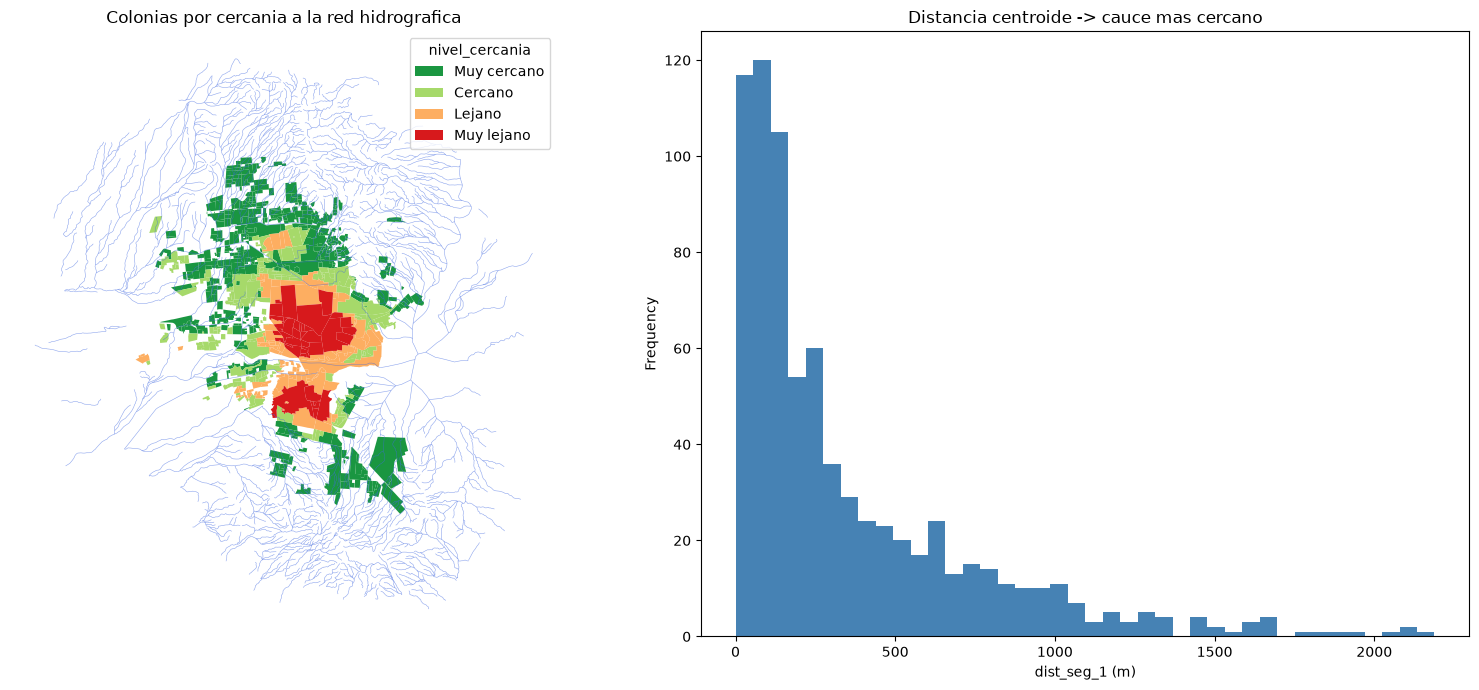

In [11]:
# verificacion visual: colonias por nivel de cercania + red hidrografica
colores_nivel = {
    "Muy cercano": "#1a9641",
    "Cercano": "#a6d96a",
    "Lejano": "#fdae61",
    "Muy lejano": "#d7191c",
}
plot_cols = colonias_ciudad.set_index("colonia_id").join(
    cercanos[["nivel_cercania"]]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for nivel, color in colores_nivel.items():
    plot_cols[plot_cols["nivel_cercania"] == nivel].plot(
        ax=axes[0], color=color, edgecolor="none", label=nivel
    )
hl.plot(ax=axes[0], color="royalblue", linewidth=0.4, alpha=0.6)
axes[0].legend(title="nivel_cercania")
axes[0].set_title("Colonias por cercania a la red hidrografica")
axes[0].set_axis_off()

cercanos["dist_seg_1"].plot.hist(ax=axes[1], bins=40, color="steelblue")
axes[1].set_xlabel("dist_seg_1 (m)")
axes[1].set_title("Distancia centroide -> cauce mas cercano")
plt.tight_layout()

## Calidad de atributos y correlación (dentro de la ciudad)

El universo son los **428 segmentos `hl` únicos** que resultaron entre los 3 más cercanos a alguna colonia. Se verifica:

1. **Códigos de "no disponible"** — según el documento técnico del INEGI, los segmentos deshabilitados (`ENABLED = 0`) reciben indicadores -1/0 en lugar de valores hidromorfométricos reales.
2. **Valores extremos** — `ARBSUM_1` puede tener una escala muy distinta a `ORDER_1`/`LEVEL_1`.
3. **Correlación** entre las tres variables, ahora restringida a la ciudad.

In [12]:
# universo: segmentos unicos cercanos a colonias (dedup por ID)
segs_ciudad = (
    segmentos_colonia[["segmento", "ORDER_1", "LEVEL_1", "ARBSUM_1"]]
    .drop_duplicates("segmento")
    .merge(
        hl[["ID", "ENABLED", "CONDICION", "subcuenca"]],
        left_on="segmento",
        right_on="ID",
    )
    .drop(columns="ID")
)
print(f"{len(segs_ciudad)} segmentos unicos")

# los -1/0 son codigos de "no disponible" en segmentos ENABLED=0?
print("\nENABLED x (ORDER_1 == -1):")
print(
    pd.crosstab(segs_ciudad["ENABLED"], segs_ciudad["ORDER_1"] == -1).to_string()
)
print("\nENABLED x (ARBSUM_1 == 0):")
print(
    pd.crosstab(segs_ciudad["ENABLED"], segs_ciudad["ARBSUM_1"] == 0).to_string()
)

con_codigos = segs_ciudad[
    (segs_ciudad["ORDER_1"] == -1) | (segs_ciudad["ARBSUM_1"] == 0)
]
print("\nSegmentos con codigos -1/0:")
print(con_codigos.to_string(index=False))

# cuantas colonias los tienen entre sus 3 cercanos
ids_codigos = set(con_codigos["segmento"])
afectadas = segmentos_colonia[
    segmentos_colonia["segmento"].isin(ids_codigos)
]["colonia_id"].unique()
print(f"\n{len(afectadas)} colonias tienen un segmento deshabilitado entre sus 3 cercanos")
print("colonia_id:", afectadas.tolist())

428 segmentos unicos

ENABLED x (ORDER_1 == -1):
ORDER_1  False  True 
ENABLED              
0            0      3
1          425      0

ENABLED x (ARBSUM_1 == 0):
ARBSUM_1  False  True 
ENABLED               
0             0      3
1           425      0

Segmentos con codigos -1/0:
segmento  ORDER_1  LEVEL_1  ARBSUM_1  ENABLED    CONDICION        subcuenca
 2985937       -1       -1       0.0        0 INTERMITENTE subc_r_son_hillo
 2987473       -1       -1       0.0        0 INTERMITENTE subc_r_son_hillo
 3089129       -1       -1       0.0        0 INTERMITENTE    subc_la_manga

7 colonias tienen un segmento deshabilitado entre sus 3 cercanos
colonia_id: ['2603000010068', '2603000010341', '2603000010424', '2603000010574', '2603000010688', '2603000010745', '2603000010834']


       ORDER_1  LEVEL_1  ARBSUM_1
count    428.0    428.0     428.0
mean       1.8      3.3    9300.3
std        1.0      1.4   17247.7
min       -1.0     -1.0       0.0
25%        1.0      2.0    1106.5
50%        2.0      3.0    3443.6
75%        2.2      4.0    8570.7
max        4.0      7.0  139833.8

Top 5 ARBSUM_1 (m acumulados aguas arriba):
segmento  ORDER_1  LEVEL_1    ARBSUM_1     subcuenca
 3092934        4        3 139833.7864 subc_la_manga
 3088715        4        3 127889.6847 subc_la_manga
 3093912        4        3 104765.9594 subc_la_manga
 3092769        4        3 103383.4242 subc_la_manga
 3090184        4        3  97959.6143 subc_la_manga


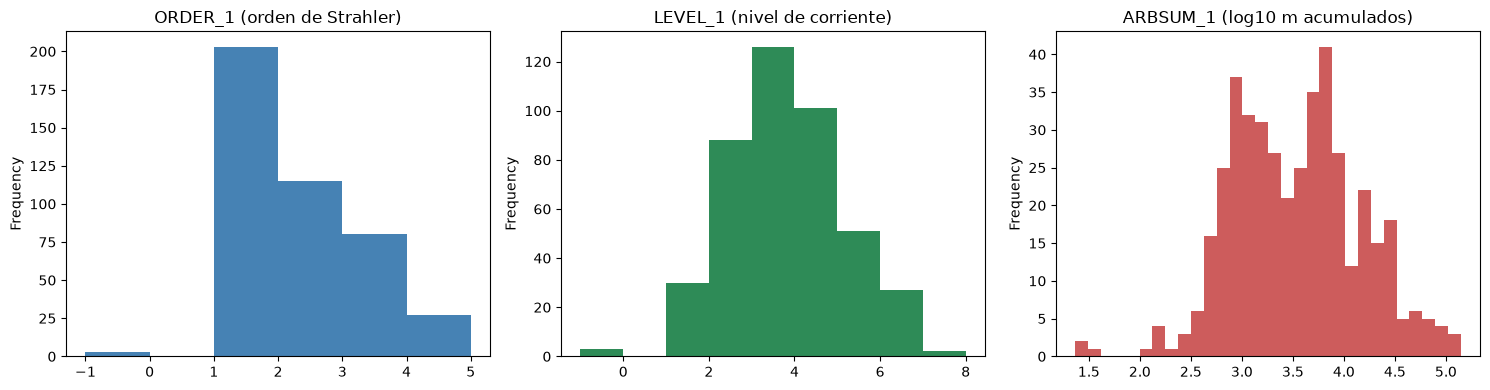

In [13]:
# extremos y escala: ARBSUM_1 corre en metros acumulados, dos ordenes de
# magnitud por encima de ORDER_1 y LEVEL_1
print(segs_ciudad[["ORDER_1", "LEVEL_1", "ARBSUM_1"]].describe().round(1).to_string())
print("\nTop 5 ARBSUM_1 (m acumulados aguas arriba):")
print(
    segs_ciudad.nlargest(5, "ARBSUM_1")[
        ["segmento", "ORDER_1", "LEVEL_1", "ARBSUM_1", "subcuenca"]
    ].to_string(index=False)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
segs_ciudad["ORDER_1"].plot.hist(ax=axes[0], bins=range(-1, 6), color="steelblue")
axes[0].set_title("ORDER_1 (orden de Strahler)")
segs_ciudad["LEVEL_1"].plot.hist(ax=axes[1], bins=range(-1, 9), color="seagreen")
axes[1].set_title("LEVEL_1 (nivel de corriente)")
np.log10(segs_ciudad.loc[segs_ciudad["ARBSUM_1"] > 0, "ARBSUM_1"]).plot.hist(
    ax=axes[2], bins=30, color="indianred"
)
axes[2].set_title("ARBSUM_1 (log10 m acumulados)")
plt.tight_layout()

425 segmentos habilitados

Pearson:
          ORDER_1  LEVEL_1  ARBSUM_1
ORDER_1     1.000   -0.458     0.720
LEVEL_1    -0.458    1.000    -0.325
ARBSUM_1    0.720   -0.325     1.000

Spearman:
          ORDER_1  LEVEL_1  ARBSUM_1
ORDER_1     1.000   -0.420     0.862
LEVEL_1    -0.420    1.000    -0.432
ARBSUM_1    0.862   -0.432     1.000

Referencia red completa (autoEDA subc_hermosillo_hl, 45,968 habilitados):
ORDER_1~ARBSUM_1 +0.87 | ORDER_1~LEVEL_1 -0.52 | LEVEL_1~ARBSUM_1 -0.55


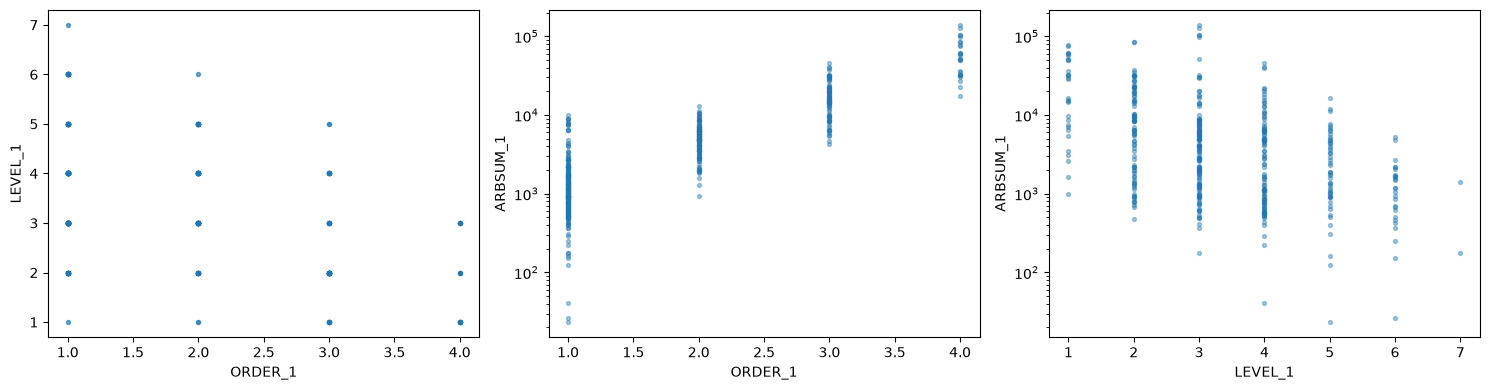

In [14]:
# correlaciones sobre los segmentos habilitados (los -1/0 son codigos, no datos)
segs_ok = segs_ciudad[segs_ciudad["ENABLED"] == 1]
vars_hidro = ["ORDER_1", "LEVEL_1", "ARBSUM_1"]

print(f"{len(segs_ok)} segmentos habilitados\n")
print("Pearson:")
print(segs_ok[vars_hidro].corr().round(3).to_string())
print("\nSpearman:")
print(segs_ok[vars_hidro].corr(method="spearman").round(3).to_string())
print(
    "\nReferencia red completa (autoEDA subc_hermosillo_hl, 45,968 habilitados):\n"
    "ORDER_1~ARBSUM_1 +0.87 | ORDER_1~LEVEL_1 -0.52 | LEVEL_1~ARBSUM_1 -0.55"
)

# scatter matrix de los 3 pares
pares = [("ORDER_1", "LEVEL_1"), ("ORDER_1", "ARBSUM_1"), ("LEVEL_1", "ARBSUM_1")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (x, y) in zip(axes, pares):
    ax.scatter(segs_ok[x], segs_ok[y], s=8, alpha=0.4)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    if "ARBSUM" in y:
        ax.set_yscale("log")
plt.tight_layout()

## Features por colonia y clustering

Se eliminan las filas con segmentos `ENABLED = 0` (sus -1/0 son códigos, no datos) y se agrega `segmentos_colonia` a **una fila por colonia** con 4 estadísticas sobre sus segmentos cercanos:

- `Order_mediana`, `Order_max` — mediana y máximo del orden de Strahler
- `Level_1_mediana`, `Level_1_min` — mediana y mínimo del nivel (1 = cauce principal)

Después se estandarizan esas 4 features junto con `nivel_cercania` (codificada como ordinal: Muy cercano=0 … Muy lejano=3) y se aplica **K-Means con k elegido por el método del codo** — la curva de inercia queda visible por si se quiere ajustar a ojo.

In [15]:
# quitar las filas cuyo segmento esta deshabilitado (-1/0 son codigos INEGI)
sc = segmentos_colonia.merge(
    hl[["ID", "ENABLED"]], left_on="segmento", right_on="ID", how="left"
).drop(columns="ID")
n_antes = len(sc)
sc = sc[sc["ENABLED"] == 1]
print(f"{n_antes - len(sc)} filas eliminadas (segmentos ENABLED=0)")

# una fila por colonia con las 4 estadisticas de sus segmentos cercanos
features_colonia = (
    sc.groupby("colonia_id")
    .agg(
        Order_mediana=("ORDER_1", "median"),
        Order_max=("ORDER_1", "max"),
        Level_1_mediana=("LEVEL_1", "median"),
        Level_1_min=("LEVEL_1", "min"),
    )
    .reset_index()
)

colonias_features = colonias_hidrografia.merge(
    features_colonia, on="colonia_id", how="left"
)
sin_features = colonias_features["Order_mediana"].isna().sum()
print(f"{colonias_features.shape[0]} filas; {sin_features} colonias sin segmentos habilitados cercanos")
colonias_features.head()

10 filas eliminadas (segmentos ENABLED=0)
762 filas; 0 colonias sin segmentos habilitados cercanos


,colonia_id,sector,id_seg_1,dist_seg_1,id_seg_2,dist_seg_2,id_seg_3,dist_seg_3,nivel_cercania,Order_mediana,Order_max,Level_1_mediana,Level_1_min
0,2603000010001,Sur,13226367,1004.576261,13221079,1019.775681,13224080,1022.626486,Lejano,3.0,3,3.0,3
1,2603000010002,Norte,13225503,33.295447,13222640,47.250747,13222082,870.857664,Muy cercano,1.0,1,4.0,3
2,2603000010003,Centro,2984475,1311.015283,2986818,1342.716226,2987476,1781.224643,Muy lejano,2.0,2,3.0,3
3,2603000010004,Sur,13221079,419.319850,13226367,476.028969,13222638,476.028969,Cercano,3.0,3,3.0,3
4,2603000010005,Norte,13222640,519.087825,13225503,550.827093,13222082,1338.042870,Lejano,1.0,1,4.0,3


k elegido por el codo: 4


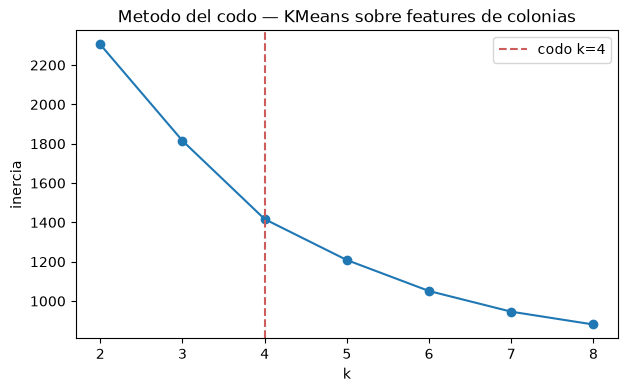

In [23]:
from sklearn.preprocessing import StandardScaler

# nivel_cercania entra como ordinal (0 = Muy cercano ... 3 = Muy lejano)
nivel_ord = {n: i for i, n in enumerate(niveles)}
colonias_features["nivel_cercania_ord"] = (
    colonias_features["nivel_cercania"].map(nivel_ord).astype(float)
)

features_clust = [
    "Order_mediana", "Order_max",
    "Level_1_mediana", "Level_1_min",
    "nivel_cercania_ord",
]
X = StandardScaler().fit_transform(colonias_features[features_clust].dropna())

# metodo del codo: inercia k=2..8, codo = maxima distancia a la cuerda
ks = np.arange(2, 9)
inertias = np.array(
    [
        KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_
        for k in ks
    ]
)
v = np.array([ks[-1] - ks[0], inertias[-1] - inertias[0]])
w = np.column_stack([ks - ks[0], inertias - inertias[0]])
dist_cuerda = np.abs(v[0] * w[:, 1] - v[1] * w[:, 0]) / np.linalg.norm(v)
K = int(ks[np.argmax(dist_cuerda)])
print(f"k elegido por el codo: {K}")

plt.figure(figsize=(7, 4))
plt.plot(ks, inertias, "o-")
plt.axvline(K, color="indianred", linestyle="--", label=f"codo k={K}")
plt.xlabel("k"); plt.ylabel("inercia"); plt.legend()
plt.title("Metodo del codo — KMeans sobre features de colonias");

cluster_hidro
0    186
1    161
2    180
3    235

Medias por cluster (escala original):
               Order_mediana  Order_max  Level_1_mediana  Level_1_min  nivel_cercania_ord
cluster_hidro                                                                            
0                       1.09       1.15             3.23         2.98                1.89
1                       3.30       3.49             1.91         1.76                0.53
2                       1.28       1.62             4.72         4.21                0.32
3                       1.34       2.31             2.69         2.11                0.20

cluster x sector:
sector         Centro  Norte  Sur
cluster_hidro                    
0                  98     26   62
1                  16    113   32
2                  38     75   67
3                  26    184   25


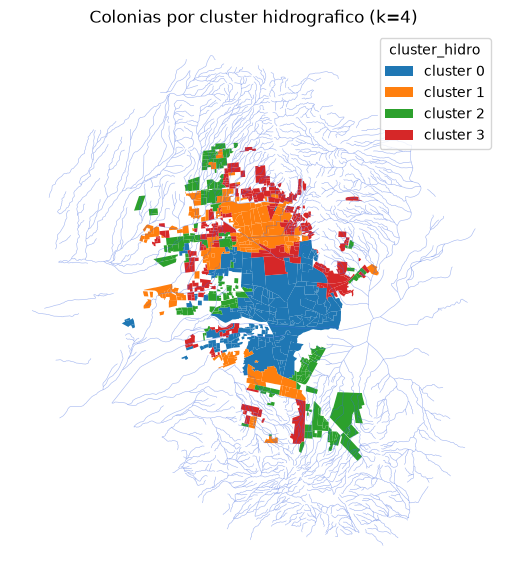

In [17]:
km_hidro = KMeans(n_clusters=K, n_init=10, random_state=42)
mask_ok = colonias_features[features_clust].notna().all(axis=1)
colonias_features.loc[mask_ok, "cluster_hidro"] = km_hidro.fit_predict(X)
colonias_features["cluster_hidro"] = colonias_features["cluster_hidro"].astype(
    "Int64"
)

print(colonias_features["cluster_hidro"].value_counts().sort_index().to_string())
print("\nMedias por cluster (escala original):")
print(
    colonias_features.groupby("cluster_hidro", observed=False)[features_clust]
    .mean()
    .round(2)
    .to_string()
)
print("\ncluster x sector:")
print(
    pd.crosstab(colonias_features["cluster_hidro"], colonias_features["sector"])
    .to_string()
)

# mapa de clusters: un color por cluster
plot_clusters = colonias_ciudad.set_index("colonia_id").join(
    colonias_features.set_index("colonia_id")[["cluster_hidro"]]
)
colores_cluster = plt.get_cmap("tab10").colors

fig, ax = plt.subplots(figsize=(9, 7))
for c in sorted(plot_clusters["cluster_hidro"].dropna().unique()):
    plot_clusters[plot_clusters["cluster_hidro"] == c].plot(
        ax=ax,
        color=colores_cluster[int(c) % len(colores_cluster)],
        edgecolor="none",
        label=f"cluster {int(c)}",
    )
hl.plot(ax=ax, color="royalblue", linewidth=0.4, alpha=0.5)
ax.legend(title="cluster_hidro")
ax.set_title(f"Colonias por cluster hidrografico (k={K})")
ax.set_axis_off()

## Contexto hidrográfico: exportación y comparativos por cluster

El cluster de cada colonia pasa a llamarse **`contexto_hidrografico`** y se agrega a la tabla ancha → `colonias_hidrografia_cd_hermosillo.csv`.

Con ese contexto se repiten las barras por km² de las libretas 06/07/08, pero el denominador ya no es el área del sector Norte/Centro/Sur sino el **área de cada cluster** (suma de las colonias que lo forman):

- **avisos / km²** = (menciones de colonia + cruces geocodificados) / km² — libreta 06
- **llamadas / km²** — solo los **grupos de superficie** (`inundacion_directa` + `fenomeno_hidrometeorologico`) — libreta 07
- **baches / km²** — libreta 08

In [18]:
# exportar: la tabla ancha + contexto_hidrografico (= cluster_hidro)
colonia_contexto = colonias_features.set_index("colonia_id")["cluster_hidro"]

export = colonias_hidrografia.merge(
    colonias_features[["colonia_id", "cluster_hidro"]].rename(
        columns={"cluster_hidro": "contexto_hidrografico"}
    ),
    on="colonia_id",
    how="left",
)
export.to_csv(
    EXPERIMENT / "colonias_hidrografia_cd_hermosillo.csv", index=False
)
print(
    f"colonias_hidrografia_cd_hermosillo.csv: {export.shape[0]} filas, "
    f"{export['contexto_hidrografico'].isna().sum()} sin contexto"
)

# denominador: km2 de cada contexto = suma de areas de sus colonias
area_ctx = colonias_ciudad[["colonia_id", "geometry"]].copy()
area_ctx["contexto"] = area_ctx["colonia_id"].map(colonia_contexto)
contexto_area = area_ctx.groupby("contexto")["geometry"].apply(
    lambda g: g.area.sum() / 1e6
)
contexto_area.index = contexto_area.index.astype(int)
print("\nkm2 por contexto_hidrografico:")
print(contexto_area.round(1).to_string())

colonias_hidrografia_cd_hermosillo.csv: 762 filas, 0 sin contexto

km2 por contexto_hidrografico:
contexto
0    47.0
1    29.2
2    28.1
3    28.1


In [19]:
# avisos por km2 (patron nb06): menciones de colonia + cruces geocodificados
publicaciones = pd.read_csv(DATA / "processed/aguah/publicaciones_aguah.csv")
ubicaciones = pd.read_csv(
    DATA / "processed/aguah/ubicaciones_aviso.csv", dtype={"colonia_id": str}
)
menciones = ubicaciones.merge(
    publicaciones[["post_id", "event_type"]], on="post_id", how="left"
)
menciones_colonia = menciones[menciones["location_type"] == "colonia"]

geocod = menciones["match_method"] == "cruce_geocodificado"
cruces = gpd.GeoDataFrame(
    menciones[geocod].reset_index(drop=True),
    geometry=gpd.points_from_xy(
        menciones.loc[geocod, "lon"], menciones.loc[geocod, "lat"]
    ),
    crs="EPSG:4326",
).to_crs(METRICO)

# contexto del cruce: el poligono de colonia donde cae
cruces_col = gpd.sjoin(
    cruces[["geometry"]],
    colonias_ciudad[["colonia_id", "geometry"]],
    how="left",
    predicate="within",
).drop(columns="index_right")
cruces_col = cruces_col[~cruces_col.index.duplicated(keep="first")]

avisos_colonia = pd.DataFrame(
    {
        "menciones": menciones_colonia.groupby("colonia_id").size(),
        "cruces": cruces_col.groupby("colonia_id").size(),
    }
)
avisos_colonia["contexto"] = colonia_contexto.reindex(avisos_colonia.index)
avisos_ctx = (
    avisos_colonia.dropna(subset=["contexto"])
    .groupby("contexto")[["menciones", "cruces"]]
    .sum()
)
avisos_ctx["avisos_por_km2"] = (
    (avisos_ctx["menciones"] + avisos_ctx["cruces"]) / contexto_area
)
print(
    f"{len(cruces_col.dropna(subset=['colonia_id']))} / {len(cruces)} cruces "
    "dentro de una colonia de la ciudad"
)
print(avisos_ctx.round(2).to_string())

1370 / 1467 cruces dentro de una colonia de la ciudad
          menciones  cruces  avisos_por_km2
contexto                                   
0            3956.0   510.0           95.11
1            4667.0   439.0          174.68
2            2112.0   212.0           82.65
3            3618.0   209.0          136.02


In [20]:
# llamadas por km2 (patron nb07): solo los grupos de superficie
# (inundacion_directa + fenomeno_hidrometeorologico); el CSV ya trae
# colonia_id resuelto por el pipeline (catalogo + equivalencias)
GRUPOS_SUPERFICIE = ["inundacion_directa", "fenomeno_hidrometeorologico"]

llamadas = pd.read_csv(DATA / "processed/llamadas_911/llamadas_911_hermosillo.csv")
superficie = llamadas[
    llamadas["grupo_incidente"].isin(GRUPOS_SUPERFICIE)
].copy()
superficie["contexto"] = (
    superficie["colonia_id"].astype("Int64").astype(str).map(colonia_contexto)
)
con_contexto_ll = superficie.dropna(subset=["contexto"])
llamadas_ctx = con_contexto_ll.groupby("contexto").size() / contexto_area
print(
    f"{len(superficie)} llamadas de grupos de superficie "
    f"({superficie['grupo_incidente'].value_counts().to_dict()}); "
    f"{superficie['colonia_id'].isna().sum()} sin colonia; "
    f"{len(con_contexto_ll)} con contexto"
)
print(llamadas_ctx.round(2).to_string())

481 llamadas de grupos de superficie ({'inundacion_directa': 454, 'fenomeno_hidrometeorologico': 27}); 111 sin colonia; 369 con contexto
contexto
0    3.15
1    4.28
2    1.00
3    2.42


In [21]:
# baches por km2 (patron nb08): el CSV ya trae colonia_id espacial
baches = pd.read_csv(
    DATA / "processed/bachometro/baches_hermosillo_colonia_filled.csv"
)
baches["contexto"] = (
    baches["colonia_id"].astype("Int64").astype(str).map(colonia_contexto)
)
con_contexto_b = baches.dropna(subset=["contexto"])
baches_ctx = con_contexto_b.groupby("contexto").size() / contexto_area
print(
    f"{baches['colonia_id'].isna().sum()} baches sin colonia; "
    f"{len(con_contexto_b)} con contexto"
)
print(baches_ctx.round(2).to_string())

598 baches sin colonia; 38209 con contexto
contexto
0    317.39
1    304.98
2    210.41
3    301.19


          avisos  llamadas  baches
contexto                          
0          95.11      3.15  317.39
1         174.68      4.28  304.98
2          82.65      1.00  210.41
3         136.02      2.42  301.19


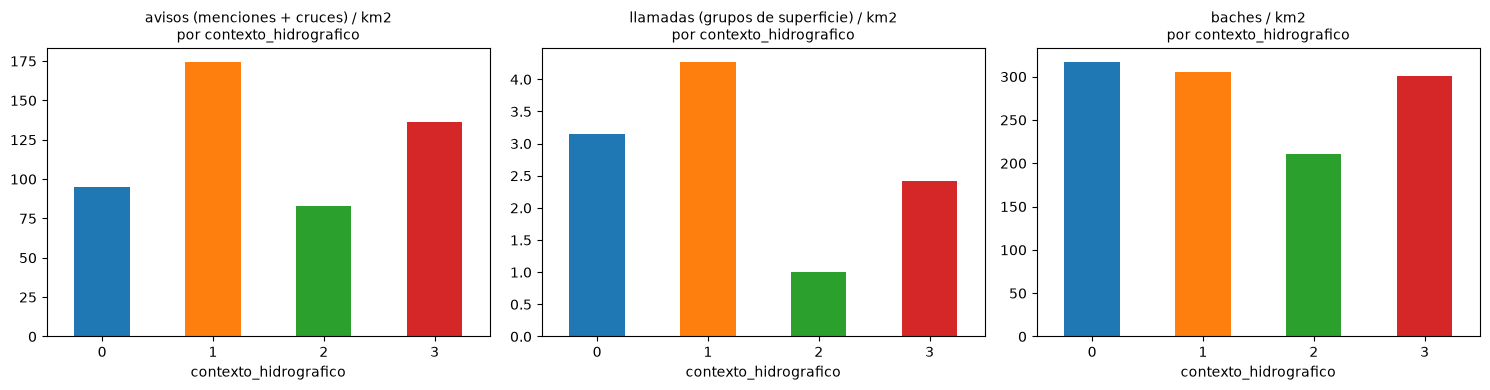

In [22]:
# comparativo por contexto: las 3 metricas por km2, mismo color que el mapa
tasas_ctx = pd.DataFrame(
    {
        "avisos": avisos_ctx["avisos_por_km2"],
        "llamadas": llamadas_ctx,
        "baches": baches_ctx,
    }
).sort_index()
print(tasas_ctx.round(2).to_string())

titulos = [
    "avisos (menciones + cruces) / km2",
    "llamadas (grupos de superficie) / km2",
    "baches / km2",
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, titulo in zip(axes, tasas_ctx.columns, titulos):
    colores = [
        colores_cluster[int(c) % len(colores_cluster)] for c in tasas_ctx.index
    ]
    tasas_ctx[col].plot.bar(ax=ax, rot=0, color=colores)
    ax.set_title(f"{titulo}\npor contexto_hidrografico", fontsize=10)
    ax.set_xlabel("contexto_hidrografico")
plt.tight_layout()

### Relación temporal: solo julio–septiembre

Mismas tres barras por km² pero restringidas a los **meses de lluvia** (jul–sep, todos los años agrupados): si los contextos capturan exposición real a cauces, el contraste entre clusters debería acentuarse en temporada.

jul-sep -> menciones colonia: 4528, cruces en colonia: 347, llamadas superficie: 332, baches: 10237
          avisos  llamadas  baches
contexto                          
0          29.00      2.92   81.84
1          55.69      3.63   88.36
2          26.67      0.92   53.99
3          40.02      2.24   81.50


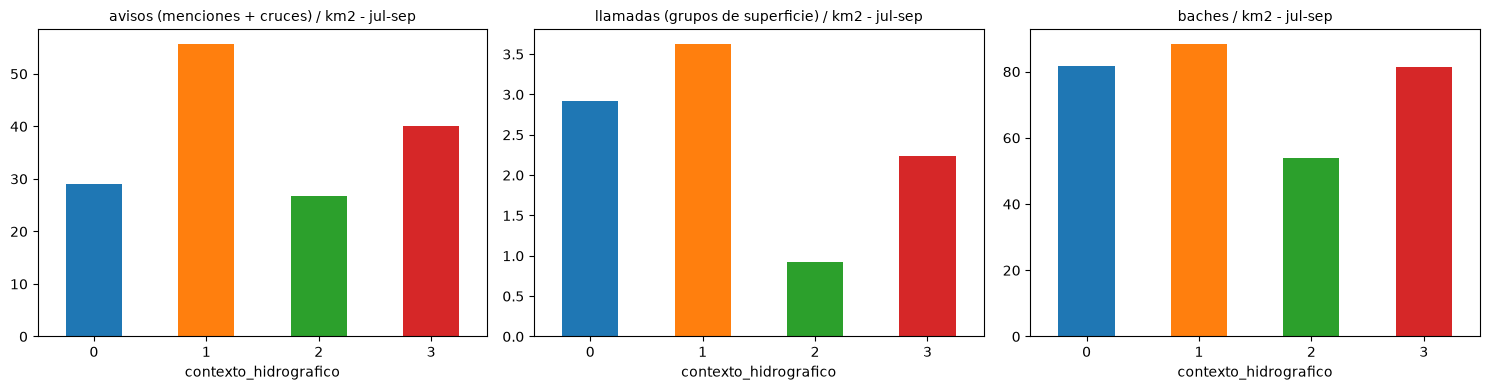

In [23]:
# mismo comparativo 1x3 pero solo julio-septiembre (temporada de lluvias)
MESES_LLUVIA = [7, 8, 9]

# avisos: el mes viene de la publicacion (publicaciones_aguah.month)
men_mes = menciones.merge(
    publicaciones[["post_id", "month"]], on="post_id", how="left"
)
men_col_j = men_mes[
    (men_mes["location_type"] == "colonia") & men_mes["month"].isin(MESES_LLUVIA)
]
cruces_j = cruces.merge(
    publicaciones[["post_id", "month"]], on="post_id", how="left"
)
cruces_col_j = gpd.sjoin(
    cruces_j[cruces_j["month"].isin(MESES_LLUVIA)][["geometry"]],
    colonias_ciudad[["colonia_id", "geometry"]],
    how="left",
    predicate="within",
).drop(columns="index_right")
cruces_col_j = cruces_col_j[~cruces_col_j.index.duplicated(keep="first")]

avisos_col_j = pd.DataFrame(
    {
        "menciones": men_col_j.groupby("colonia_id").size(),
        "cruces": cruces_col_j.groupby("colonia_id").size(),
    }
)
avisos_col_j["contexto"] = colonia_contexto.reindex(avisos_col_j.index)
avisos_ctx_j = (
    avisos_col_j.dropna(subset=["contexto"])
    .groupby("contexto")[["menciones", "cruces"]]
    .sum()
)
avisos_ctx_j["avisos_por_km2"] = (
    (avisos_ctx_j["menciones"] + avisos_ctx_j["cruces"]) / contexto_area
)

# llamadas de superficie: mes de la fecha del registro 911
superficie["mes"] = pd.to_datetime(superficie["fecha"]).dt.month
con_ll_j = superficie[
    superficie["mes"].isin(MESES_LLUVIA) & superficie["contexto"].notna()
]
llamadas_ctx_j = con_ll_j.groupby("contexto").size() / contexto_area

# baches: mes de la fecha del reporte
baches["mes"] = pd.to_datetime(baches["date"], errors="coerce").dt.month
con_b_j = baches[baches["mes"].isin(MESES_LLUVIA) & baches["contexto"].notna()]
baches_ctx_j = con_b_j.groupby("contexto").size() / contexto_area

print(
    f"jul-sep -> menciones colonia: {len(men_col_j)}, "
    f"cruces en colonia: {len(cruces_col_j.dropna(subset=['colonia_id']))}, "
    f"llamadas superficie: {len(con_ll_j)}, baches: {len(con_b_j)}"
)

tasas_ctx_j = pd.DataFrame(
    {
        "avisos": avisos_ctx_j["avisos_por_km2"],
        "llamadas": llamadas_ctx_j,
        "baches": baches_ctx_j,
    }
).sort_index()
print(tasas_ctx_j.round(2).to_string())

titulos_j = [
    "avisos (menciones + cruces) / km2 - jul-sep",
    "llamadas (grupos de superficie) / km2 - jul-sep",
    "baches / km2 - jul-sep",
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, titulo in zip(axes, tasas_ctx_j.columns, titulos_j):
    colores = [
        colores_cluster[int(c) % len(colores_cluster)] for c in tasas_ctx_j.index
    ]
    tasas_ctx_j[col].plot.bar(ax=ax, rot=0, color=colores)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("contexto_hidrografico")
plt.tight_layout()

## Resumen

Se genera `notebook_experimentation_data/colonias_hidrografia.csv` con una fila por cada una de las colonias de la ciudad (762) y las 9 columnas pedidas:

- **`sector`** decide la banda latitudinal (Norte/Centro/Sur); el match PDU (`sector_pdu`, `metodo_sector`) quedó como diagnóstico dentro de la libreta.
- **`id_seg_*` / `dist_seg_*`** salen del centroide de cada colonia contra los segmentos `hl` en EPSG:6372 — todas las filas resuelven sus 3 segmentos sin recurrir al fallback de 15 km.
- **`nivel_cercania`** reparte las colonias en 4 grupos ordenados por distancia al cauce más cercano. El sesgo geográfico ya observado en la libreta 08 se repite: el sector Centro concentra las colonias más lejanas (la red densa está en la periferia norte y poniente), algo a considerar si la variable se usa como predictor.
- **`segmentos_colonia`** queda en formato largo (762 × 3 = 2,286 filas): `colonia_id`, `n_seg`, `segmento`, `distancia_m` y los atributos `ORDER_1`/`LEVEL_1`/`ARBSUM_1` recuperados del `hl` por `ID` — insumo para el feature engineering posterior.

**Calidad de atributos (428 segmentos únicos dentro de la ciudad):**

- Los valores `-1`/`0` son **códigos de "no disponible"** del INEGI, no datos: solo aparecen en los 3 segmentos `ENABLED = 0` de la ciudad (ciclos, `CONDICION = INTERMITENTE`). Ningún segmento habilitado los tiene. **7 colonias** tienen uno de esos segmentos entre sus 3 cercanos → esas filas deben tratarse como faltantes al construir features.
- **`ARBSUM_1` tiene una escala dos órdenes de magnitud mayor** que `ORDER_1` (1–4) y `LEVEL_1` (1–7): mediana ~3.4 km, máximo ~140 km acumulados aguas arriba, cola derecha larga → candidata a transformación log o escalado antes de alimentar modelos.
- **Correlación dentro de la ciudad** (425 habilitados): `ORDER_1 ~ ARBSUM_1` ≈ **+0.86 Spearman** — se mantiene fuerte como en la red completa (0.87): ambos miden casi lo mismo y son redundantes entre sí. `LEVEL_1` correlaciona negativamente con ambos (~-0.4): el cauce principal (nivel 1) es donde orden y acumulación son máximas.

**Features y clustering por colonia:**

- Tras filtrar los segmentos `ENABLED = 0` de la tabla larga, `colonias_features` agrega a una fila por colonia: `Order_mediana`, `Order_max`, `Level_1_mediana`, `Level_1_min`.
- K-Means sobre las 4 features + `nivel_cercania` (ordinal) estandarizadas, con **k = 4 elegido por el método del codo** → `cluster_hidro`.
- **`colonias_hidrografia_cd_hermosillo.csv`**: la tabla ancha + `contexto_hidrografico` (= cluster), 762 filas sin nulos.

**Qué significa cada `contexto_hidrografico`** (medias de las features por cluster; `nivel_ord` 0 = Muy cercano … 3 = Muy lejano):

| contexto | colonias | Order_med | Order_max | Level_med | Level_min | nivel_ord | Significado |
|---|---|---|---|---|---|---|---|
| **0** | 186 | 1.1 | 1.2 | 3.2 | 3.0 | 1.9 | **Lejos de la red**: solo arroyos de cabecera (orden ~1, nivel ~3) y además alejados — son las colonias del Centro, con poca exposición a cauces |
| **1** | 161 | 3.3 | 3.5 | 1.9 | 1.8 | 0.5 | **Junto a colectores**: cauces de orden alto y nivel bajo (cauce principal) a distancia media — ribereños del Norte |
| **2** | 180 | 1.3 | 1.6 | 4.7 | 4.2 | 0.3 | **Arroyos menores muy cerca**: red de drenaje fina (orden 1, nivel alto) pegada a la colonia |
| **3** | 235 | 1.3 | 2.3 | 2.7 | 2.1 | 0.2 | **Los más cercanos**: nivel de cercanía mínimo; entre sus 3 segmentos suele haber algún cauce de nivel bajo (Level_min ~2) mezclado con arroyos — franja norte |

**Comparativos por contexto (tasas por km² del cluster, no del sector):**

| contexto | km² | avisos/km² | llamadas/km² * | baches/km² |
|---|---|---|---|---|
| 0 — lejos de la red (Centro) | 47.0 | 95 | 3.2 | 317 |
| 1 — junto a colectores | 29.2 | 175 | 4.3 | 305 |
| 2 — arroyos menores muy cerca | 28.1 | 83 | 1.0 | 210 |
| 3 — los más cercanos (Norte) | 28.1 | 136 | 2.4 | 301 |

\* llamadas = solo grupos de superficie (`inundacion_directa` + `fenomeno_hidrometeorologico`, 481 llamadas / 369 con contexto).

**Solo julio–septiembre** (temporada de lluvias, todos los años): el contraste se acentúa — el contexto 1 lidera las **tres** métricas (avisos 55.7, llamadas 3.6, baches 88.4 por km²), incluidos los baches que en el año completo dominaba el contexto 0. La exposición a cauces principales se manifiesta sobre todo en temporada.